# MACHINE LEARNING  CA1
# Student: Mariana Garcia 
# Student n#: 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel("Real estate valuation data set.xlsx")

In [3]:
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


In [4]:
df.tail()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
409,410,2013.000000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.666667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250000,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000000,8.1,104.81010,5,24.96674,121.54067,52.5
413,414,2013.500000,6.5,90.45606,9,24.97433,121.54310,63.9


In [5]:
data_dictionary = pd.DataFrame({
    "Variable": [
        "No",
        "X1 transaction date",
        "X2 house age",
        "X3 distance to the nearest MRT station",
        "X4 number of convenience stores",
        "X5 latitude",
        "X6 longitude",
        "Y house price of unit area"
    ],
    "Description": [
        "Transaction record identifier",
        "Date of property transaction",
        "Age of the property",
        "Distance to nearest MRT station",
        "Number of nearby convenience stores",
        "Geographic latitude",
        "Geographic longitude",
        "House price per unit area"
    ],
    "Unit": [
        "Record number",
        "Decimal year",
        "Years",
        "Metres",
        "Number of stores",
        "Decimal degrees",
        "Decimal degrees",
        "10,000 TWD per ping"
    ],
    "Role": [
        "Identifier",
        "Predictor",
        "Predictor",
        "Predictor",
        "Predictor",
        "Predictor",
        "Predictor",
        "Target"
    ]
})

display(data_dictionary)


,Variable,Description,Unit,Role
0,No,Transaction record identifier,Record number,Identifier
1,X1 transaction date,Date of property transaction,Decimal year,Predictor
2,X2 house age,Age of the property,Years,Predictor
3,X3 distance to the nearest MRT station,Distance to nearest MRT station,Metres,Predictor
4,X4 number of convenience stores,Number of nearby convenience stores,Number of stores,Predictor
5,X5 latitude,Geographic latitude,Decimal degrees,Predictor
6,X6 longitude,Geographic longitude,Decimal degrees,Predictor
7,Y house price of unit area,House price per unit area,"10,000 TWD per ping",Target


# Target Variable = "Y house price of unit area"

# Dataset Structure and Data Types



In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


The dataset contains 414 observations and 8 columns. All variables are numerical, with 6 columns stored as float64 and 2 as int64.

The initial inspection shows that all columns contain 414 non-null values, indicating that there are no missing values detected at this stage.

The No column represents a transaction identifier and will be excluded from predictive modelling because it does not describe a property characteristic.

# Checking the size and data types

In [7]:
df.shape

(414, 8)

The Real Estate Valuation dataset contains 414 property transaction records and eight variables. Six variables describe property characteristics, including house age, transaction date, proximity to public transport, nearby convenience stores and geographical location. The dependent variable is house price per unit area. The transaction identifier (No) will be excluded from predictive modelling because it does not represent a property characteristic.

# Checking missing values

In [8]:
df.isnull().sum()

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

# Checking duplicates

In [9]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicates excluding ID:", df.drop(columns=["No"]).duplicated().sum())

Duplicate rows: 0
Duplicates excluding ID: 0


The dataset was examined for missing values and duplicate records as part of the initial data quality assessment.
No missing values were identified across the 414 observations. Additionally, no duplicate records were found, either when considering all columns or when excluding the transaction identifier (No).
Therefore, no missing-value imputation or duplicate removal was required at this stage.

# Descriptive statistics

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
No,414.0,207.500000,119.655756,1.000000,104.250000,207.500000,310.750000,414.000000
X1 transaction date,414.0,2013.148953,0.281995,2012.666667,2012.916667,2013.166667,2013.416667,2013.583333
X2 house age,414.0,17.712560,11.392485,0.000000,9.025000,16.100000,28.150000,43.800000
X3 distance to the nearest MRT station,414.0,1083.885689,1262.109595,23.382840,289.324800,492.231300,1454.279000,6488.021000
X4 number of convenience stores,414.0,4.094203,2.945562,0.000000,1.000000,4.000000,6.000000,10.000000
X5 latitude,414.0,24.969030,0.012410,24.932070,24.963000,24.971100,24.977455,25.014590
X6 longitude,414.0,121.533361,0.015347,121.473530,121.528085,121.538630,121.543305,121.566270
Y house price of unit area,414.0,37.980193,13.606488,7.600000,27.700000,38.450000,46.600000,117.500000


# Creating a copy of the dataset before  carrying out changes

In [11]:
df_original= df.copy()

# Renaming Columns 

In [12]:
df= df.rename(columns={
    "X1 transaction date": "Transaction_Date",
    "X2 house age": "House_Age",
    "X3 distance to the nearest MRT station": "Distance_to_MRT",
    "X4 number of convenience stores": "Convenience_Stores",
    "X5 latitude": "Latitude",
    "X6 longitude": "Longitude",
    "Y house price of unit area": "House_Price_per_Unit_Area"
})

df.head()

,No,Transaction_Date,House_Age,Distance_to_MRT,Convenience_Stores,Latitude,Longitude,House_Price_per_Unit_Area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


As part of data preprocessing, the columns were renamed to improve readability and make the dataset easier to work with during Exploratory Data Analysis (EDA) and Machine Learning.

# Dropping column No

In [13]:
df=df.drop(columns=["No"])

The No column was removed because it is only a transaction identifier and does not provide useful information about the properties. Including it in the model could introduce irrelevant patterns and affect the predictions.

In [14]:
df

,Transaction_Date,House_Age,Distance_to_MRT,Convenience_Stores,Latitude,Longitude,House_Price_per_Unit_Area
0,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...
409,2013.000000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,2012.666667,5.6,90.45606,9,24.97433,121.54310,50.0
411,2013.250000,18.8,390.96960,7,24.97923,121.53986,40.6
412,2013.000000,8.1,104.81010,5,24.96674,121.54067,52.5


# EDA 

In [68]:
df.nunique

<bound method DataFrame.nunique of      Transaction_Date  House_Age  Distance_to_MRT  Convenience_Stores  \
0         2012.916667       32.0         84.87882                  10   
1         2012.916667       19.5        306.59470                   9   
2         2013.583333       13.3        561.98450                   5   
3         2013.500000       13.3        561.98450                   5   
4         2012.833333        5.0        390.56840                   5   
..                ...        ...              ...                 ...   
409       2013.000000       13.7       4082.01500                   0   
410       2012.666667        5.6         90.45606                   9   
411       2013.250000       18.8        390.96960                   7   
412       2013.000000        8.1        104.81010                   5   
413       2013.500000        6.5         90.45606                   9   

     Latitude  Longitude  House_Price_per_Unit_Area  
0    24.98298  121.54024          

# Exploratory Data Analysis *** Distribution of Variables ***

In [15]:
# Continuos Variables histograms

In [16]:
continuous_cols = [
    "Transaction_Date",
    "House_Age",
    "Distance_to_MRT",
    "Latitude",
    "Longitude",
    "House_Price_per_Unit_Area"
]

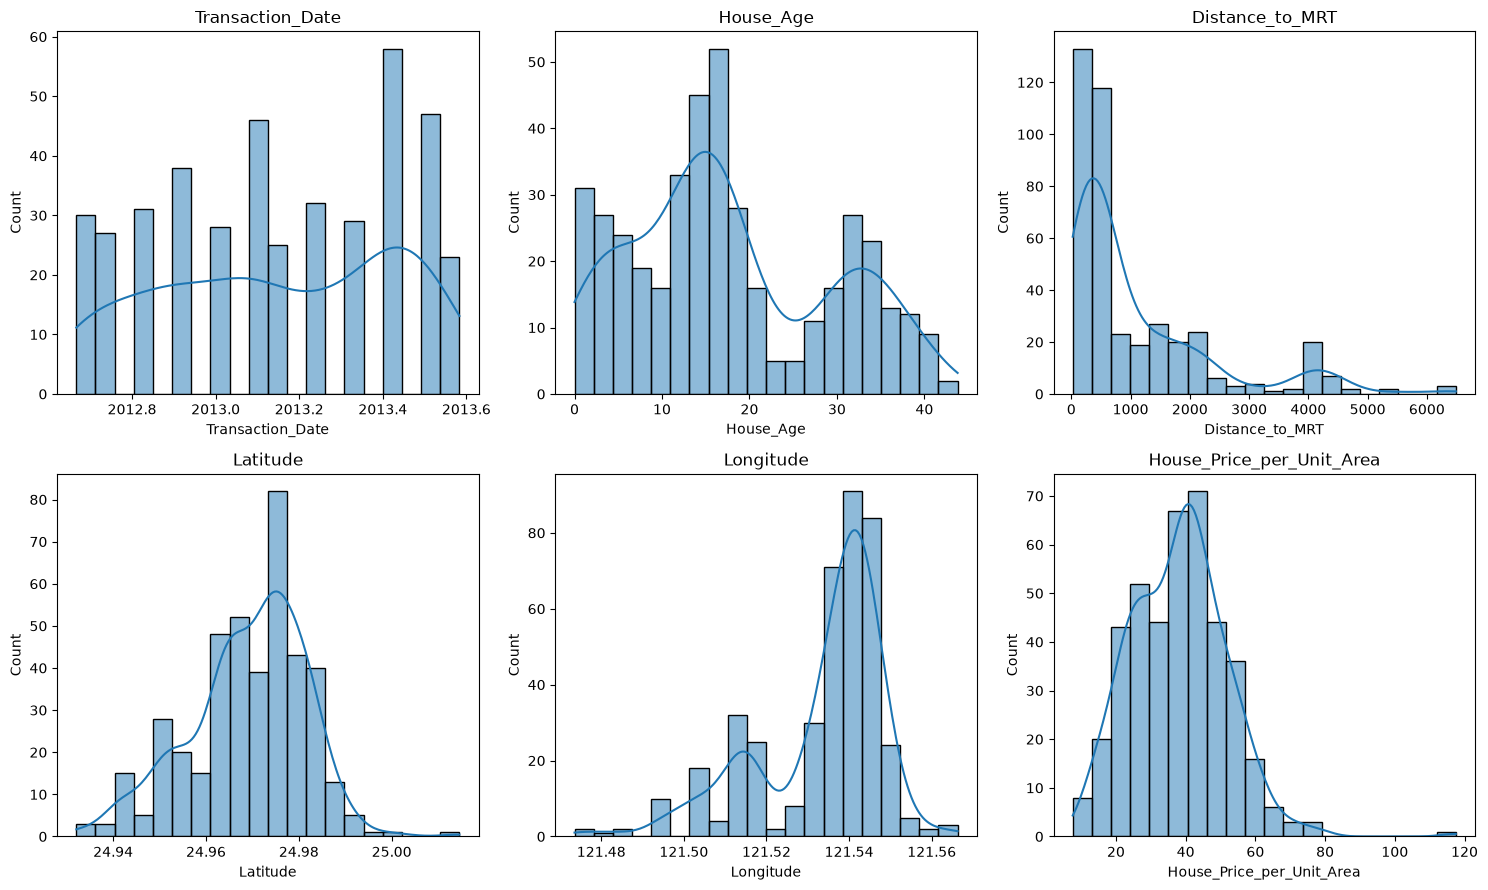

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flatten(), continuous_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=20,
        kde=True,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()


# Distribution of Convenience Stores

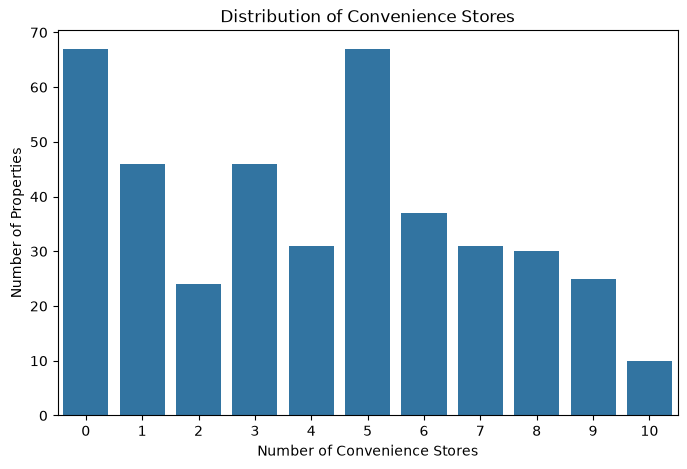

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Convenience_Stores"
)

plt.title("Distribution of Convenience Stores")
plt.xlabel("Number of Convenience Stores")
plt.ylabel("Number of Properties")
plt.show()


# Distribution of Transaction Dates histplot

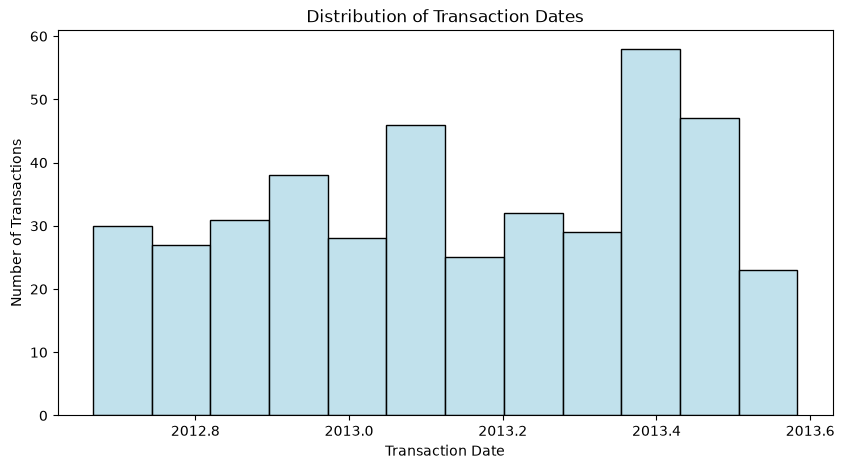

In [30]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Transaction_Date",
    bins=12,
    color="lightblue"
)

plt.title("Distribution of Transaction Dates")
plt.xlabel("Transaction Date")
plt.ylabel("Number of Transactions")
plt.show()

# Relationships with house price

In [20]:
features = [
    "House_Age",
    "Distance_to_MRT",
    "Convenience_Stores",
    "Transaction_Date"
]

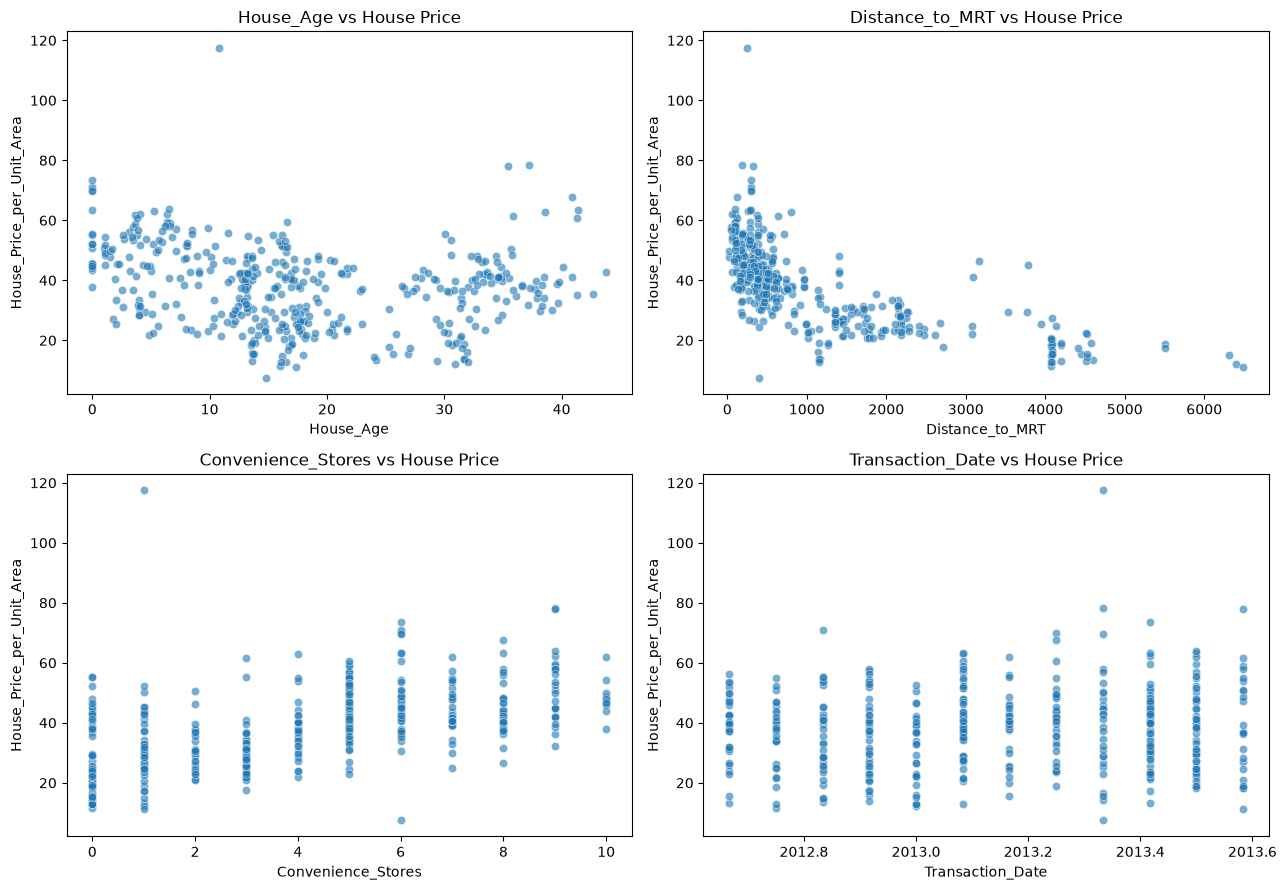

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flatten(), features):
    sns.scatterplot(
        data=df,
        x=col,
        y="House_Price_per_Unit_Area",
        ax=ax,
        alpha=0.6
    )
    ax.set_title(f"{col} vs House Price")

plt.tight_layout()
plt.show()

# Correlation Map 

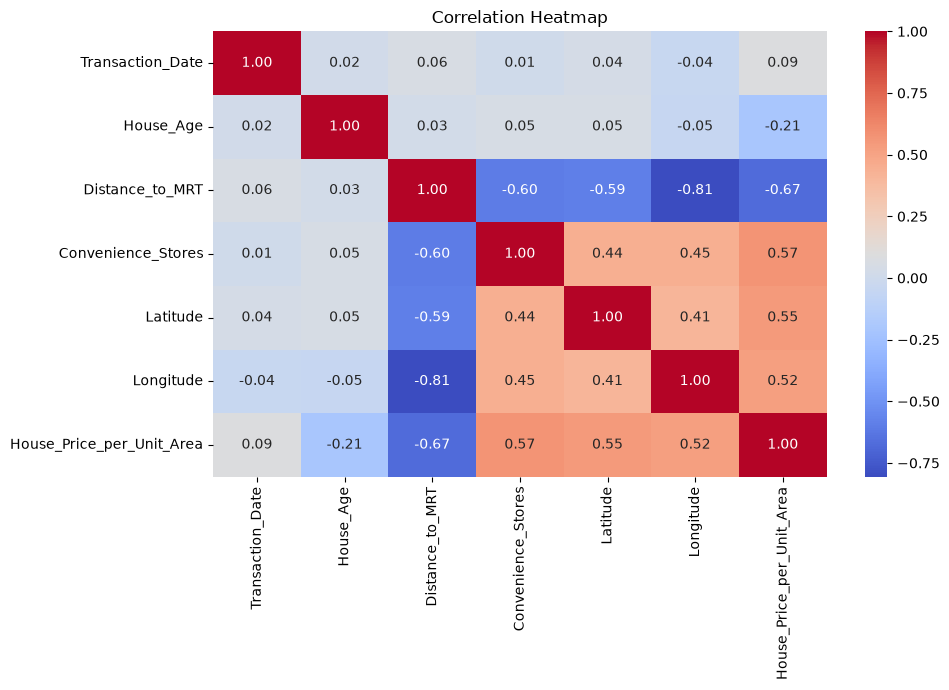

In [22]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm",fmt=".2f")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# Geographic scatterplot Property locations

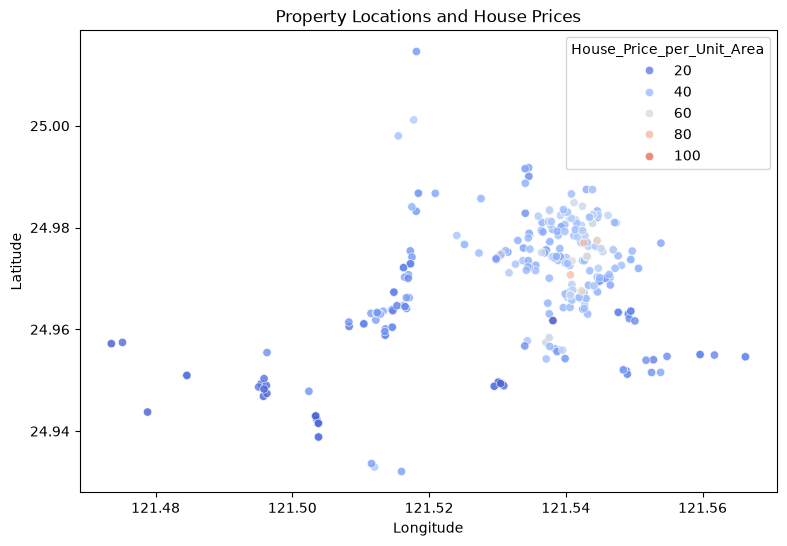

In [23]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Longitude", y="Latitude",hue="House_Price_per_Unit_Area",palette="coolwarm",alpha=0.8)
plt.title("Property Locations and House Prices")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# Distance to MRT Station vs House Price

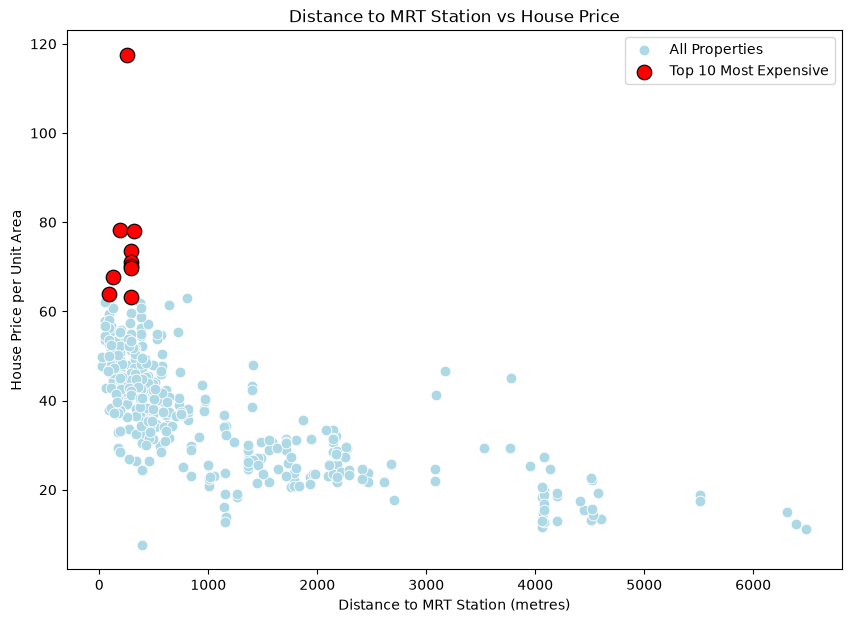

In [24]:
plt.figure(figsize=(10, 7))

expensive = df.nlargest(10, "House_Price_per_Unit_Area")
sns.scatterplot(
    data=df,
    x="Distance_to_MRT",
    y="House_Price_per_Unit_Area",
    color="lightblue",
    s=60,
    label="All Properties"
)

sns.scatterplot(
    data=expensive,
    x="Distance_to_MRT",
    y="House_Price_per_Unit_Area",
    color="red",
    s=110,
    edgecolor="black",
    label="Top 10 Most Expensive"
)

plt.title("Distance to MRT Station vs House Price")
plt.xlabel("Distance to MRT Station (metres)")
plt.ylabel("House Price per Unit Area")
plt.legend()
plt.show()

# Property Location and House prices

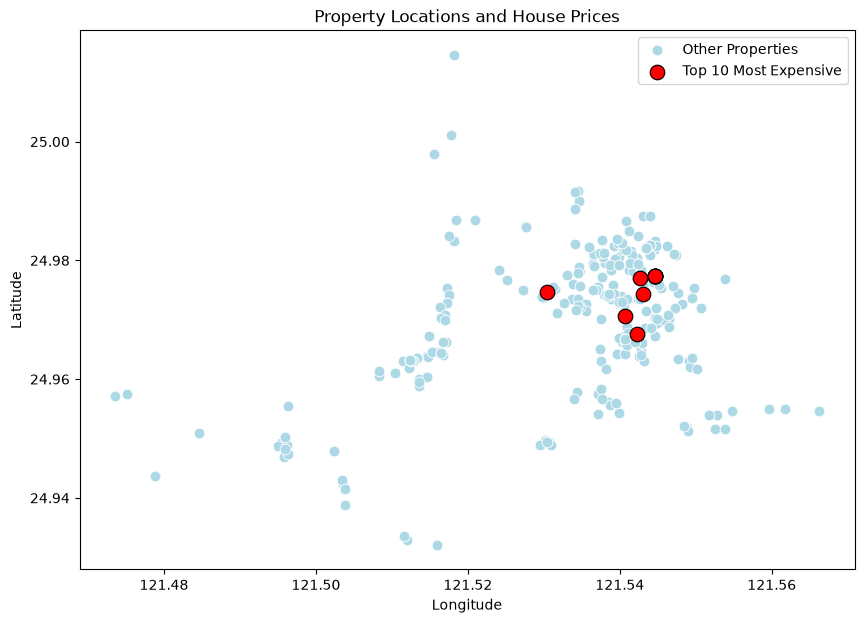

In [25]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Longitude",
    y="Latitude",
    color="lightblue",
    s=60,
    label="Other Properties"
)

expensive = df.nlargest(10, "House_Price_per_Unit_Area")
sns.scatterplot(
    data=expensive,
    x="Longitude",
    y="Latitude",
    color="red",
    s=110,
    edgecolor="black",
    label="Top 10 Most Expensive"
)

plt.title("Property Locations and House Prices")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()

# Average House Price by Number of Convenience Stores

In [26]:
df[["Convenience_Stores", "House_Price_per_Unit_Area"]].corr()

,Convenience_Stores,House_Price_per_Unit_Area
Convenience_Stores,1.000000,0.571005
House_Price_per_Unit_Area,0.571005,1.000000


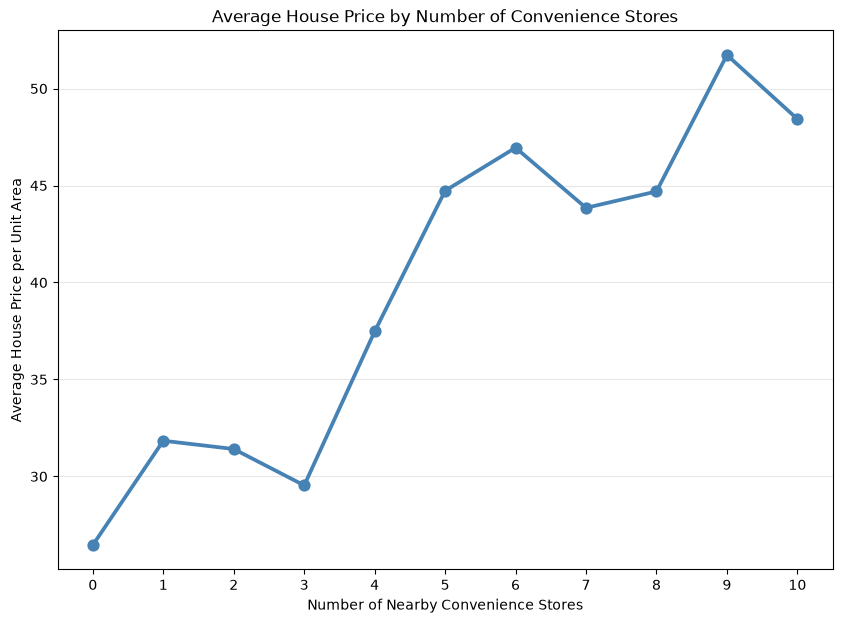

In [27]:
plt.figure(figsize=(10, 7))

sns.pointplot(
    data=df,
    x="Convenience_Stores",
    y="House_Price_per_Unit_Area",
    estimator="mean",
    errorbar=None,
    color="steelblue",
    markers="o",
    linestyles="-"
)

plt.title("Average House Price by Number of Convenience Stores")
plt.xlabel("Number of Nearby Convenience Stores")
plt.ylabel("Average House Price per Unit Area")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Checking Outliers

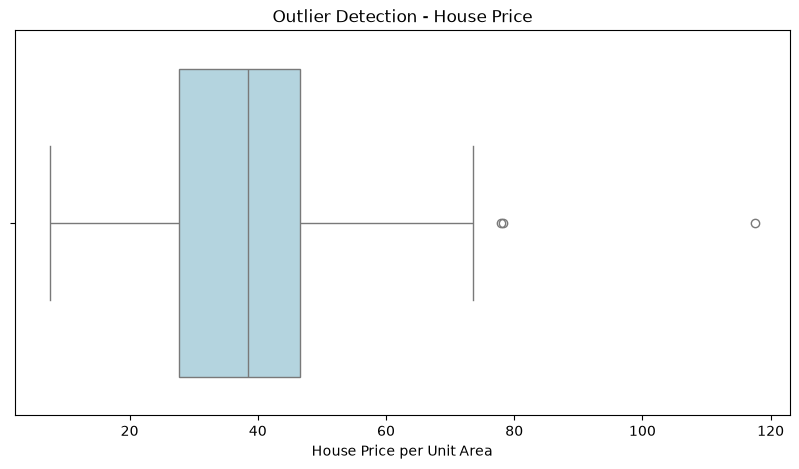

In [47]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="House_Price_per_Unit_Area",
    color="lightblue"
)

plt.title("Outlier Detection - House Price")
plt.xlabel("House Price per Unit Area")
plt.show()

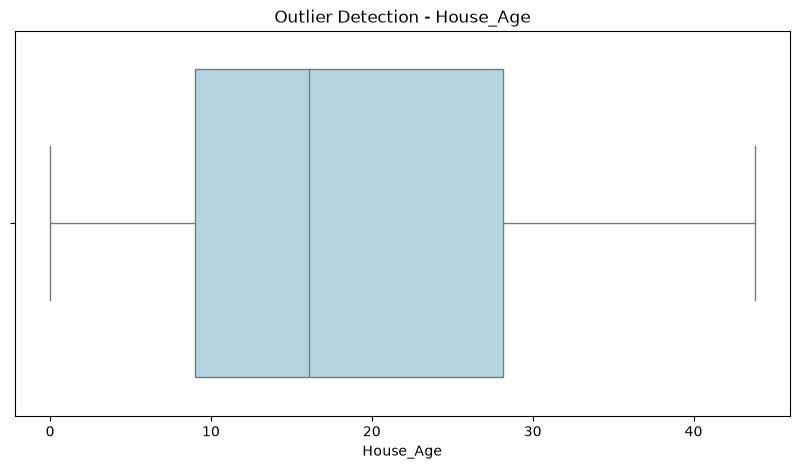

In [48]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="House_Age",
    color="lightblue"
)

plt.title("Outlier Detection - House_Age")
plt.xlabel("House_Age")
plt.show()

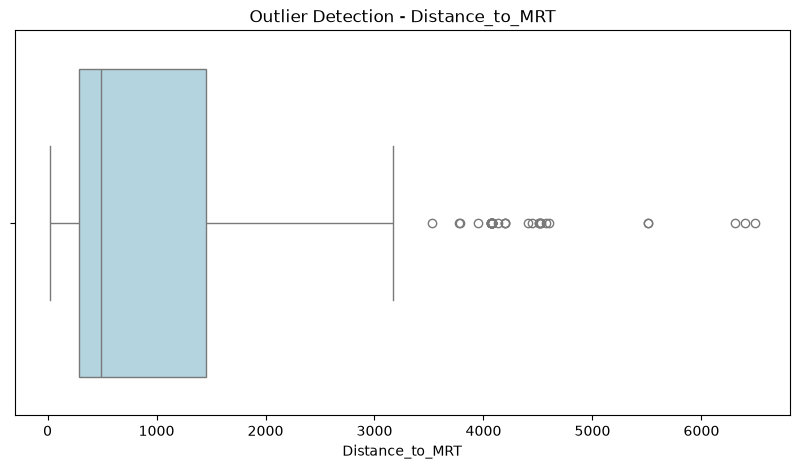

In [49]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Distance_to_MRT",
    color="lightblue"
)

plt.title("Outlier Detection - Distance_to_MRT")
plt.xlabel("Distance_to_MRT")
plt.show()

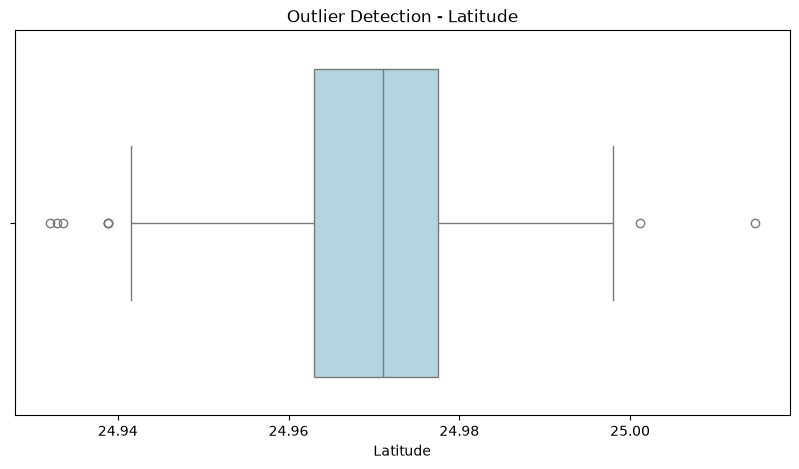

In [50]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Latitude",
    color="lightblue"
)

plt.title("Outlier Detection - Latitude")
plt.xlabel("Latitude")
plt.show()

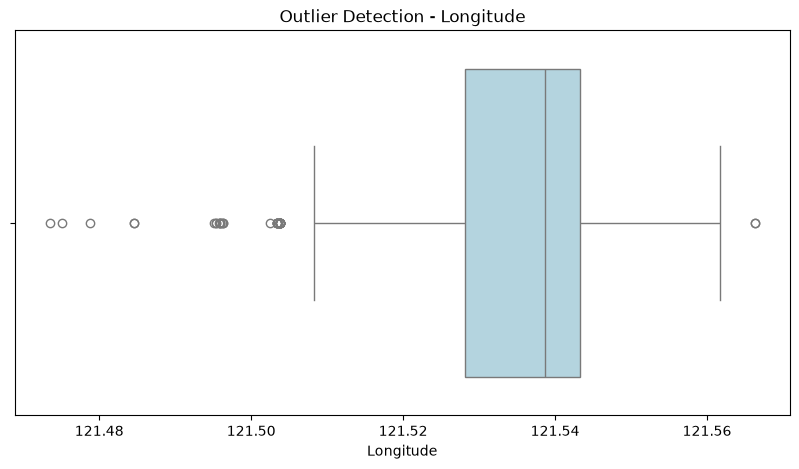

In [53]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x= "Longitude",
    color="lightblue"
)

plt.title("Outlier Detection - Longitude")
plt.xlabel("Longitude")
plt.show()

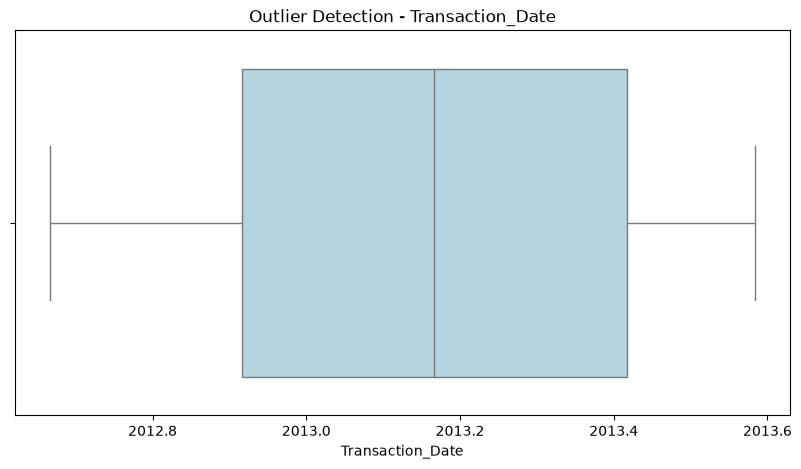

In [54]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x= "Transaction_Date",
    color="lightblue"
)

plt.title("Outlier Detection - Transaction_Date")
plt.xlabel("Transaction_Date")
plt.show()

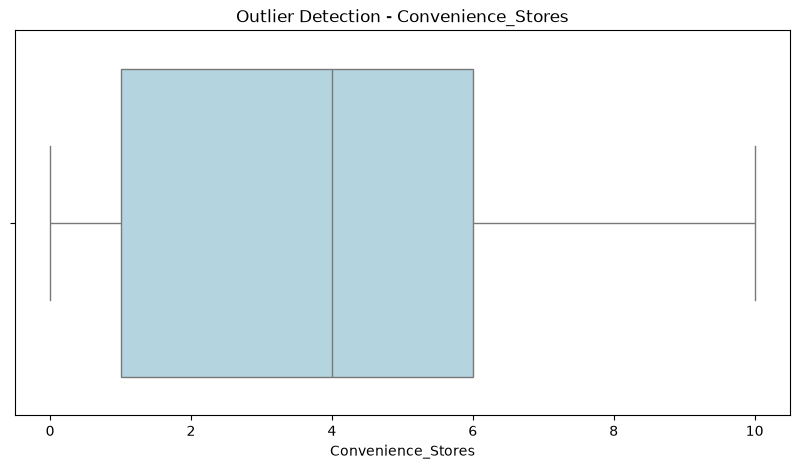

In [57]:
plt.figure(figsize=(10,5))
sns.boxplot(
    data=df,
    x=df["Convenience_Stores"],
    color="lightblue")

plt.title("Outlier Detection - Convenience_Stores")
plt.xlabel("Convenience_Stores")
plt.show()

In [60]:
columns = [
    "Transaction_Date",
    "House_Age",
    "Distance_to_MRT",
    "Convenience_Stores",
    "Latitude",
    "Longitude",
    "House_Price_per_Unit_Area"
]

In [61]:
outlier_summary = []

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    )

    outlier_summary.append({
        "Variable": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Outliers": outliers.sum(),
        "Percentage (%)": round(outliers.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Variable,Lower Bound,Upper Bound,Outliers,Percentage (%)
0,Transaction_Date,2012.17,2014.17,0,0.00
1,House_Age,-19.66,56.84,0,0.00
2,Distance_to_MRT,-1458.11,3201.71,37,8.94
3,Convenience_Stores,-6.50,13.50,0,0.00
4,Latitude,24.94,25.00,8,1.93
5,Longitude,121.51,121.57,35,8.45
6,House_Price_per_Unit_Area,-0.65,74.95,3,0.72


### Outlier Detection and Analysis

Outlier detection was performed using the Interquartile Range (IQR) method across all seven numerical variables in the Real Estate Valuation dataset, containing 414 observations.

The analysis identified 37 potential outliers in Distance to MRT (8.94%), 35 in Longitude (8.45%), 8 in Latitude (1.93%) and 3 in House Price per Unit Area (0.72%).

No outliers were detected in Transaction Date, House Age or Convenience Stores using the IQR method.

The highest proportion of outliers was observed in Distance to MRT, suggesting that some properties are located considerably farther from MRT stations than the majority of observations.

Outliers in geographic coordinates may represent genuine differences in property locations, while unusual house prices may reflect legitimate variations in property value.

Further investigation is required before deciding whether any observations should be removed or transformed, as removing valid observations could reduce the representativeness of the dataset.

# Further Outlier  Investigation 

In [69]:
df_original = df.copy()
df_clean = df.copy()

In [ ]:
Treat Distance to MRT

In [72]:
import numpy as np

df_clean["Log_Distance_to_MRT"] = np.log1p(
    df_clean["Distance_to_MRT"]
)

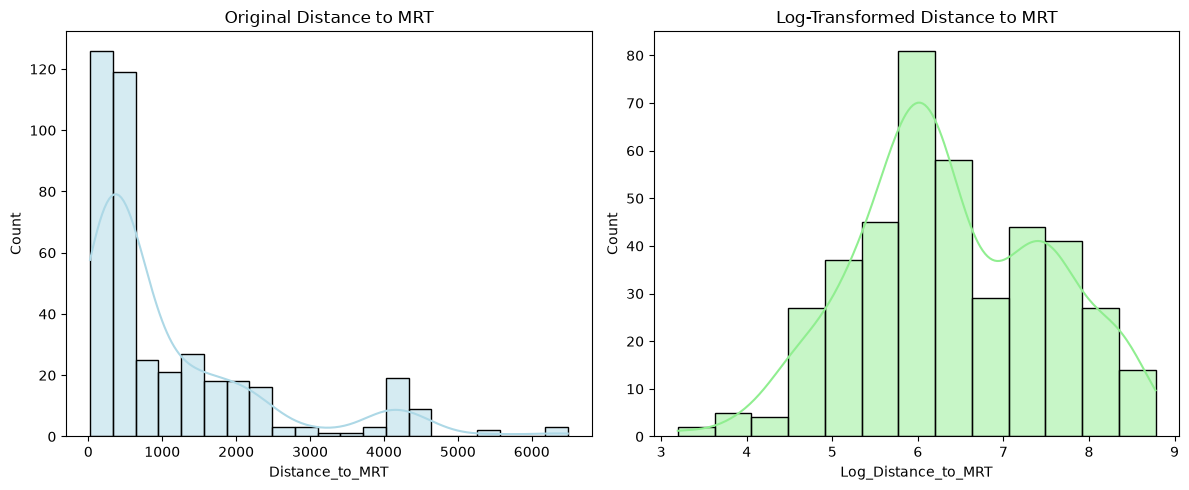

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=df_clean,
    x="Distance_to_MRT",
    kde=True,
    color="lightblue",
    ax=axes[0]
)
axes[0].set_title("Original Distance to MRT")

sns.histplot(
    data=df_clean,
    x="Log_Distance_to_MRT",
    kde=True,
    color="lightgreen",
    ax=axes[1]
)
axes[1].set_title("Log-Transformed Distance to MRT")

plt.tight_layout()
plt.show()

In [88]:
print(
    "Original skewness:",
    df_clean["Distance_to_MRT"].skew()
)

print(
    "Transformed skewness:",
    df_clean["Log_Distance_to_MRT"].skew()
)

Original skewness: 1.8887565801256048
Transformed skewness: 0.06061933799186839


# Treatment of Distance to MRT Outliers

The original Distance to MRT variable showed a strongly positively skewed distribution, with most properties located relatively close to MRT stations and a smaller number located considerably farther away.

A logarithmic transformation using `np.log1p()` was applied to reduce the skewness and compress extreme distance values without removing any observations.

The transformed histogram showed a more balanced distribution, although some variation and multiple concentrations remained.

Both the original and log-transformed variables will be evaluated during model development to determine whether the transformation improves regression performance.

Treat Latitude and Longitude

In [83]:
df_clean[["Latitude", "Longitude"]].describe()

,Latitude,Longitude
count,414.000000,414.000000
mean,24.969030,121.533361
std,0.012410,0.015347
min,24.932070,121.473530
25%,24.963000,121.528085
50%,24.971100,121.538630
75%,24.977455,121.543305
max,25.014590,121.566270


In [84]:
invalid_locations = df_clean[
    (df_clean["Latitude"] < -90) |
    (df_clean["Latitude"] > 90) |
    (df_clean["Longitude"] < -180) |
    (df_clean["Longitude"] > 180)
]

display(invalid_locations)

,Transaction_Date,House_Age,Distance_to_MRT,Convenience_Stores,Latitude,Longitude,House_Price_per_Unit_Area,Log_Distance_to_MRT


# Treatment of Latitude and Longitude

The IQR method identified 8 potential outliers in Latitude and 35 in Longitude. Descriptive statistics and coordinate validation were performed to investigate these observations.

All coordinates were within the valid geographic ranges. As the unusual values may represent genuine property locations, the observations were retained without transformation or removal.

In [85]:
price_outliers = df_clean[
    df_clean["House_Price_per_Unit_Area"] > 74.95
]

display(price_outliers)

,Transaction_Date,House_Age,Distance_to_MRT,Convenience_Stores,Latitude,Longitude,House_Price_per_Unit_Area,Log_Distance_to_MRT
220,2013.333333,37.2,186.5101,9,24.97703,121.54265,78.3,5.233833
270,2013.333333,10.8,252.5822,1,24.97460,121.53046,117.5,5.535688
312,2013.583333,35.4,318.5292,9,24.97071,121.54069,78.0,5.766849


# House Price
Property 270 is particularly unusual because its price is much higher than the others.

However, you cannot conclude that the price is incorrect from these variables alone.

In [89]:
print("Original dataset:", df_original.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (414, 7)
Cleaned dataset: (414, 8)


## Outlier Detection and Treatment
Outliers were identified using boxplots and the Interquartile Range (IQR) method across all seven variables in the Real Estate Valuation dataset (414 observations).

### Outlier Treatment
**Distance to MRT:** 37 potential outliers were identified (8.94%). The original distribution was strongly right-skewed. A logarithmic transformation using `np.log1p()` was applied, reducing skewness while retaining all observations. The original and transformed variables will be compared during model evaluation.

**Latitude and Longitude:** 8 and 35 potential outliers were identified, respectively. All coordinates were within valid geographic ranges. These observations were retained because they may represent genuine property locations.

**House Price per Unit Area:** Three unusually high values (78.0, 78.3 and 117.5) were identified. As there was insufficient evidence that these values were incorrect, they were retained for initial modelling.

**Transaction Date, House Age and Convenience Stores:** No outliers were identified using the IQR method. These variables were retained unchanged.

### Conclusion

No observations were removed, preserving all 414 properties. A log-transformed version of Distance to MRT was created to reduce skewness.

The original and transformed distance variables will be compared during regression modelling to evaluate their impact on model performance.
